# Praktikum 5
Benchmark ANN: Recall vs Query Time

Untuk membandingkan ANN, biasanya digunakan metrics **Recall Query** (berapa banyak nearest neighbors yang ditemukan dengan benar) dan diplot dalam bentuk grafik. Grafik perbandingan ANN digambarkan dengan sumbu X sebagai **recall** dan sumbu Y sebagai **queries per second (QPS)**.

* Posisi **kanan atas** = ideal (akurat sekaligus cepat).
* Posisi **kanan bawah** = akurat tapi lambat.
* Posisi **kiri atas** = cepat tetapi kurang akurat.

Penggunaan repository `ann-benchmarks` memerlukan Docker, sehingga di sini kita akan memvisualisasikan dengan grafik sederhana yang memberikan gambaran serupa.

In [1]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

In [2]:
# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

> **Catatan efisiensi:** pada modul, index Annoy dibangun ulang di setiap pemanggilan `run_annoy`. Di sini index dibangun **sekali** lalu dipakai untuk semua nilai `search_k`, agar benchmark lebih efisien (build time tidak ikut terukur berulang).

In [3]:
# -------------------------------
# Build index sekali (Annoy & HNSW)
# -------------------------------
def build_annoy(xb, n_trees=10):
    index = AnnoyIndex(xb.shape[1], 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)
    return index

annoy_index = build_annoy(xb, n_trees=10)

hnsw_index = hnswlib.Index(space='l2', dim=d)
hnsw_index.init_index(max_elements=nb, ef_construction=200, M=16)
hnsw_index.add_items(xb)

quantizer = faiss.IndexFlatL2(d)
faiss_index = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
faiss_index.train(xb)
faiss_index.add(xb)

In [4]:
# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(index, xq, search_k=1000, k=10):
    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(index, xq, nprobe=10, k=10):
    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(index, xq, ef=100, k=10):
    index.set_ef(ef)
    start = time.time()
    I, _ = index.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(annoy_index, xq, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(faiss_index, xq, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(hnsw_index, xq, ef=ef)
    results["HNSW"].append((rec, t))

for name, vals in results.items():
    print(name)
    for rec, t in vals:
        print(f"  recall={rec:.4f}  time={t:.4f} ms/query")

Annoy
  recall=0.0248  time=0.0824 ms/query
  recall=0.0486  time=0.1983 ms/query
  recall=0.0808  time=0.3544 ms/query
  recall=0.1287  time=0.6253 ms/query
Faiss
  recall=0.0558  time=0.0100 ms/query
  recall=0.1981  time=0.0264 ms/query
  recall=0.3239  time=0.0512 ms/query
  recall=0.5031  time=0.1843 ms/query
HNSW
  recall=0.3047  time=0.1754 ms/query
  recall=0.4412  time=0.1310 ms/query
  recall=0.6096  time=0.5789 ms/query
  recall=0.7682  time=0.4814 ms/query


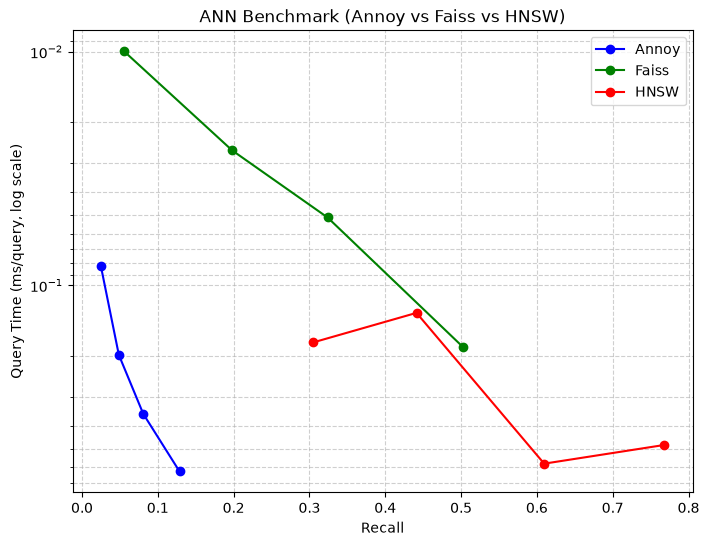

In [5]:
# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

> **Interpretasi:** Setiap kurva menunjukkan trade-off antara recall dan kecepatan. Dengan menaikkan parameter (`search_k` untuk Annoy, `nprobe` untuk FAISS, `ef` untuk HNSW), recall naik tetapi query time juga naik. Library yang kurvanya berada paling dekat ke pojok kanan-atas (recall tinggi, waktu rendah) adalah yang paling efisien.